# CONCH Opus R2 — Stain characteristics

## 1. Data source/acquisition

Use the fixed CRC-VAL and full NCT-CRC-HE-100K image sources, CONCH checkpoint/CRC prompt ensemble, and ImageNet ResNet50 V2 weights. Every reused file is checked. The reference and confirmation pools come from different image identities within NCT; this is not an independent hospital/site claim. Use the Python 3.11 environment described by the explicit imports and pins: NumPy 1.26.4, Pandas 2.2.2, SciPy 1.13.1, scikit-learn 1.5.2, scikit-image 0.24.0, OpenCV 4.10.0, Pillow 10.4.0, PyTorch 2.5.0 and torchvision 0.20.0. Set CONCH_INPUTS/CONCH_SOURCE to an existing cache.

**Environment setup before starting the kernel (Linux/CUDA 12.4):**

```bash
python3.11 -m venv .venv-conch-opus
.venv-conch-opus/bin/python -m pip install torch==2.5.0 torchvision==0.20.0 --index-url https://download.pytorch.org/whl/cu124
.venv-conch-opus/bin/python -m pip install numpy==1.26.4 scipy==1.13.1 pandas==2.2.2 scikit-learn==1.5.2 Pillow==10.4.0 pyarrow==16.1.0 scikit-image==0.24.0 statsmodels==0.14.2 opencv-python-headless==4.10.0.84 matplotlib==3.9.4 timm==0.9.16 transformers==4.40.1 tokenizers==0.19.1 huggingface-hub==0.23.5 ftfy==6.3.1 h5py==3.11.0 open_clip_torch==2.24.0 requests==2.32.3 nbformat==5.10.4 nbclient==0.10.4 nbconvert==7.16.6 ipykernel==6.29.5
.venv-conch-opus/bin/python -m ipykernel install --user --name conch-opus --display-name "conch-opus"
```

Select that kernel before Run All. The acquisition cell clones the pinned public CONCH implementation; every analysis-specific function remains inline below. Raw tiles are 224×224; the pinned public CONCH transform resizes model inputs to its default 448×448. The pixel-axis calculations use the raw-tile resolution.

In [1]:
AXIS_ID='test-02'
AXIS_TITLE='Stain characteristics'

from pathlib import Path
import os,sys,json,hashlib,io,subprocess,inspect
import numpy as np
import pandas as pd
import requests
import pyarrow.parquet as pq
from PIL import Image
from huggingface_hub import HfApi,hf_hub_download
from IPython.display import display,Image as DisplayImage
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score
INPUTS=Path(os.environ.get('CONCH_INPUTS',str(Path.cwd()/'inputs'))).resolve()
OUTPUT=Path.cwd()/'computed'/AXIS_ID
SHARED=INPUTS/'inline_opus2_predictions'
INPUTS.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True);SHARED.mkdir(parents=True,exist_ok=True)
REV='97765ecb14bf11ce7bb8779a1097d187844a67cb'
CODE_REV='141cc09c7d4ff33d8eda562bd75169b457f71a62'
MODEL_REV='f9ca9f877171a28ade80228fb195ac5d79003357'
MODEL_SHA='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c'
PROMPT_SHA='5cac7ab39a593e10d053647842401eae00b94351bd33c5edcad29b17757343e2'
LABEL_NAMES=dict(enumerate(['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']))
LABELS=list(LABEL_NAMES)
def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def display_figure(fig):
    stream=io.BytesIO();fig.savefig(stream,format='png',dpi=140,bbox_inches='tight')
    display(DisplayImage(data=stream.getvalue()));plt.close(fig)
SOURCE=Path(os.environ.get('CONCH_SOURCE',str(INPUTS.parent/'external'/'CONCH')))
if not (SOURCE/'.git').exists():
    SOURCE.parent.mkdir(parents=True,exist_ok=True)
    subprocess.run(['git','clone','https://github.com/mahmoodlab/CONCH.git',str(SOURCE)],check=True)
    subprocess.run(['git','-C',str(SOURCE),'checkout',CODE_REV],check=True)
assert subprocess.check_output(['git','-C',str(SOURCE),'rev-parse','HEAD'],text=True).strip()==CODE_REV
sys.path.insert(0,str(SOURCE))
PROMPTS=SOURCE/'prompts/crc100k_prompts_all_per_class.json'
assert sha(PROMPTS)==PROMPT_SHA
CHECKPOINT=INPUTS/'conch_checkpoint/pytorch_model.bin'
if not CHECKPOINT.exists():
    CHECKPOINT=Path(hf_hub_download('MahmoodLab/conch','pytorch_model.bin',revision=MODEL_REV,local_dir=INPUTS/'conch_checkpoint'))
assert CHECKPOINT.stat().st_size==802235437 and sha(CHECKPOINT)==MODEL_SHA
info=HfApi().dataset_info('1aurent/NCT-CRC-HE',revision=REV,files_metadata=True)
assert info.sha==REV
source_members={item.rfilename:item for item in info.siblings}
CRC_SHARDS=[
 'data/CRC_VAL_HE_7K-00000-of-00003-cce1097526b69125.parquet',
 'data/CRC_VAL_HE_7K-00001-of-00003-fbb5de8b1164f4ea.parquet',
 'data/CRC_VAL_HE_7K-00002-of-00003-2009e87e0c48fccf.parquet']
source_receipts=[]
for filename in CRC_SHARDS:
    path=INPUTS/'hf_parquet'/filename; expected=source_members[filename].lfs.sha256
    if not path.exists():path=Path(hf_hub_download('1aurent/NCT-CRC-HE',filename,repo_type='dataset',revision=REV,local_dir=INPUTS/'hf_parquet'))
    assert sha(path)==expected
    source_receipts.append(dict(filename=filename,revision=REV,sha256=expected,bytes=path.stat().st_size))

NCT_SHARDS=sorted(name for name in source_members if name.startswith('data/NCT_CRC_HE_100K-') and name.endswith('.parquet'))
assert len(NCT_SHARDS)==31
nct_sources=[]
for filename in NCT_SHARDS:
    path=INPUTS/'hf_parquet'/filename;expected=source_members[filename].lfs.sha256
    if not path.exists():path=Path(hf_hub_download('1aurent/NCT-CRC-HE',filename,repo_type='dataset',revision=REV,local_dir=INPUTS/'hf_parquet'))
    assert sha(path)==expected
    nct_sources.append(dict(filename=filename,revision=REV,sha256=expected,bytes=path.stat().st_size))
print('Verified',len(CRC_SHARDS),'CRC and',len(NCT_SHARDS),'NCT source shards')

BACKBONE=INPUTS/'resnet50-11ad3fa6.pth'
BACKBONE_SHA='11ad3fa62ca79e40addfd354a8ec4b7c75143b3038b8d2a807fbc68deab379ca'
if not BACKBONE.exists():
    with requests.get('https://download.pytorch.org/models/resnet50-11ad3fa6.pth',stream=True,timeout=180) as response:
        response.raise_for_status()
        with BACKBONE.open('wb') as out:
            for block in response.iter_content(8*1024*1024):out.write(block)
assert BACKBONE.stat().st_size==102540417 and sha(BACKBONE)==BACKBONE_SHA

/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Verified 3 CRC and 31 NCT source shards


## 2. Data processing

Compute 12 prospective pixel features on all 7,180 development images. Sort NCT image names, permute each class with seed 20261027, and select 300 reference images plus 120 disjoint confirmation images per class. Exclude decoded-pixel overlaps and confirmation images within six dHash bits of development. The reference trains the fixed comparator; confirmation outcomes do not affect selection. A separate 45-per-class development pilot supports the power calculation.

In [2]:
import cv2
from skimage.color import rgb2hed
CLASSES=list(LABEL_NAMES.values())
FEATS=['sharpness_varlap','sharpness_tenengrad','highfreq_frac','brightness','contrast_std','saturation_mean','colorfulness','tissue_frac','hematoxylin_mean','eosin_mean','he_ratio','entropy']
def features_for(img_rgb):
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    gf = g.astype(np.float64)
    # focus / sharpness
    lap = cv2.Laplacian(gf, cv2.CV_64F)
    varlap = float(lap.var())
    gx = cv2.Sobel(gf, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gf, cv2.CV_64F, 0, 1, ksize=3)
    tenengrad = float(np.mean(gx * gx + gy * gy))
    F = np.fft.fftshift(np.fft.fft2(gf))
    mag = np.abs(F)
    h, w = gf.shape
    cy, cx = h / 2.0, w / 2.0
    yy, xx = np.ogrid[:h, :w]
    r = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
    rad = min(h, w) / 8.0  # mid-frequency cutoff
    total = mag.sum() + 1e-9
    highfreq_frac = float(mag[r > rad].sum() / total)
    # intensity
    brightness = float(gf.mean())
    contrast_std = float(gf.std())
    # color
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    saturation_mean = float(hsv[:, :, 1].mean())
    R = img_rgb[:, :, 0].astype(np.float64)
    G = img_rgb[:, :, 1].astype(np.float64)
    B = img_rgb[:, :, 2].astype(np.float64)
    rg = R - G
    yb = 0.5 * (R + G) - B
    colorfulness = float(np.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * np.sqrt(rg.mean() ** 2 + yb.mean() ** 2))
    # tissue fraction: not near-white and some saturation
    white = (gf > 220) & (hsv[:, :, 1] < 25)
    tissue_frac = float(1.0 - white.mean())
    # entropy
    hist = cv2.calcHist([g], [0], None, [256], [0, 256]).ravel()
    p = hist / (hist.sum() + 1e-9)
    p = p[p > 0]
    entropy = float(-(p * np.log2(p)).sum())
    # stain color deconvolution (H&E)
    hed = rgb2hed(img_rgb.astype(np.float64) / 255.0)
    hematoxylin_mean = float(hed[:, :, 0].mean())
    eosin_mean = float(hed[:, :, 1].mean())
    he_ratio = float(hematoxylin_mean / (abs(eosin_mean) + 1e-6))
    return {
        "sharpness_varlap": varlap,
        "sharpness_tenengrad": tenengrad,
        "highfreq_frac": highfreq_frac,
        "brightness": brightness,
        "contrast_std": contrast_std,
        "saturation_mean": saturation_mean,
        "colorfulness": colorfulness,
        "tissue_frac": tissue_frac,
        "hematoxylin_mean": hematoxylin_mean,
        "eosin_mean": eosin_mean,
        "he_ratio": he_ratio,
        "entropy": entropy,
    }
def dhash(im_rgb, hs=8):
    g = cv2.cvtColor(im_rgb, cv2.COLOR_RGB2GRAY)
    r = cv2.resize(g, (hs + 1, hs), interpolation=cv2.INTER_AREA)
    diff = r[:, 1:] > r[:, :-1]
    bits = np.packbits(diff.flatten())
    return int.from_bytes(bits.tobytes(), "big")

def decode(encoded):return cv2.cvtColor(cv2.imdecode(np.frombuffer(encoded,np.uint8),cv2.IMREAD_COLOR),cv2.COLOR_BGR2RGB)
crc_records=[];crc_raw={}
for filename in CRC_SHARDS:
    p=pq.ParquetFile(INPUTS/'hf_parquet'/filename)
    for group in range(p.num_row_groups):
        for row in p.read_row_group(group,columns=['image','label']).to_pylist():
            identifier=Path(row['image']['path']).name;rgb=decode(row['image']['bytes']);crc_raw[identifier]=rgb
            crc_records.append(dict(id=identifier,label=int(row['label']),label_name=LABEL_NAMES[int(row['label'])],pixel_sha256=hashlib.sha256(np.ascontiguousarray(rgb).tobytes()).hexdigest(),dhash=dhash(rgb),**features_for(rgb)))
dev=pd.DataFrame(crc_records).sort_values('id').reset_index(drop=True);assert len(dev)==7180
population=[]
for filename in NCT_SHARDS:
    p=pq.ParquetFile(INPUTS/'hf_parquet'/filename)
    for group in range(p.num_row_groups):
        for local,row in enumerate(p.read_row_group(group,columns=['image.path','label']).to_pylist()):
            population.append(dict(shard=filename,group=group,local=local,label=int(row['label']),id=Path(row['image']['path']).name))
population=pd.DataFrame(population).sort_values('id').reset_index(drop=True);assert len(population)==100000
rng=np.random.default_rng(20261027);candidate_groups=[]
for label,part in population.groupby('label',sort=True):
    selected=part.iloc[rng.permutation(len(part))[:500]].copy();selected['draw_order']=np.arange(len(selected));candidate_groups.append(selected)
candidates=pd.concat(candidate_groups).reset_index(drop=True)
nct_raw={}
for (filename,group),part in candidates.groupby(['shard','group'],sort=True):
    images=pq.ParquetFile(INPUTS/'hf_parquet'/filename).read_row_group(int(group),columns=['image','label']).to_pylist()
    for row in part.itertuples():
        source=images[int(row.local)];assert int(source['label'])==row.label;nct_raw[row.id]=decode(source['image']['bytes'])
dev_exact=set(dev.pixel_sha256);dev_dhash=dev.dhash.to_numpy(np.uint64)
bitcounts=np.array([int(i).bit_count() for i in range(256)],dtype=np.uint8)
def minimum_hamming(value):
    xor=np.bitwise_xor(dev_dhash,np.uint64(value));return int(bitcounts[xor.view(np.uint8).reshape(-1,8)].sum(axis=1).min())
reference_rows=[];confirmation_rows=[];excluded=[];used_pixels=set()
for label,part in candidates.groupby('label',sort=True):
    nref=0;nconfirm=0
    for row in part.sort_values('draw_order').itertuples():
        rgb=nct_raw[row.id];digest=hashlib.sha256(np.ascontiguousarray(rgb).tobytes()).hexdigest();dh=dhash(rgb)
        if digest in dev_exact or digest in used_pixels:
            excluded.append(dict(id=row.id,reason='exact decoded-pixel overlap'));continue
        data=dict(id=row.id,label=int(label),label_name=LABEL_NAMES[label],pixel_sha256=digest,dhash=dh,shard=row.shard,group=int(row.group),local=int(row.local),draw_order=int(row.draw_order))
        if nref<300:
            reference_rows.append(data);used_pixels.add(digest);nref+=1
        elif nconfirm<120:
            distance=minimum_hamming(dh)
            if distance<=6:excluded.append(dict(id=row.id,reason='dHash within6 bits of development',hamming=distance));continue
            data['min_hamming_to_development']=distance;confirmation_rows.append(data);used_pixels.add(digest);nconfirm+=1
        if nref==300 and nconfirm==120:break
    assert nref==300 and nconfirm==120,(label,nref,nconfirm)
reference=pd.DataFrame(reference_rows).sort_values(['label','id']).reset_index(drop=True)
confirmation=pd.DataFrame(confirmation_rows).sort_values(['label','id']).reset_index(drop=True)
assert len(reference)==2700 and len(confirmation)==1080 and not set(reference.id)&set(confirmation.id)
reference.to_csv(OUTPUT/'reference_membership.csv',index=False);confirmation.to_csv(OUTPUT/'confirmation_membership.csv',index=False);pd.DataFrame(excluded).to_csv(OUTPUT/'exclusions.csv',index=False)
display(pd.DataFrame({'reference':reference.label_name.value_counts(),'confirmation':confirmation.label_name.value_counts(),'development':dev.label_name.value_counts()}));print('Excluded candidates',len(excluded))
# A balanced development pilot precedes the fixed1080-image confirmation analysis.
pilot_rng=np.random.default_rng(20261027)
pilot=pd.concat([part.iloc[pilot_rng.choice(len(part),45,replace=False)] for _,part in dev.groupby('label',sort=True)]).sort_values(['label','id']).reset_index(drop=True)

,reference,confirmation,development
label_name,,,
ADI,300,120,1338
BACK,300,120,847
DEB,300,120,339
LYM,300,120,634
MUC,300,120,1035
MUS,300,120,592
NORM,300,120,741
STR,300,120,421
TUM,300,120,1233


Excluded candidates 0


## 3. Axis definition and level construction

The controlled axis applies Gaussian blur sigma 0,1,2,3 to each confirmation image, using kernel 2×round(3×sigma)+1. Thus image identity and tissue class remain identical across levels. Measure Laplacian variance, brightness and saturation from every transformed image. Candidate stain and composition axes are screened in development quintiles and within tissue class.

In [3]:
def blur_rgb(img, sigma):
    if sigma <= 0:
        return img
    k = max(3, int(2 * round(3 * sigma) + 1))
    return cv2.GaussianBlur(img, (k, k), sigma)

SIGMAS=[0.,1.,2.,3.]
# Gaussian blur is an intervention on the same image at each level.
# All memberships are fixed before any confirmation predictions are calculated.
measured=[]
for sigma in SIGMAS:
    for row in confirmation.itertuples():
        rgb=blur_rgb(nct_raw[row.id],sigma);gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY).astype(np.float64);hsv=cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV)
        measured.append(dict(id=row.id,label=row.label,label_name=row.label_name,sigma=sigma,varlap=float(cv2.Laplacian(gray,cv2.CV_64F).var()),brightness=float(gray.mean()),saturation_mean=float(hsv[:,:,1].mean())))
measured=pd.DataFrame(measured)
assert measured.groupby('sigma').size().eq(1080).all()
display(measured.groupby('sigma')[['varlap','brightness','saturation_mean']].mean())
for feature in FEATS:
    edges=np.quantile(dev[feature],[0,.2,.4,.6,.8,1.]);dev[feature+'_quintile']=np.searchsorted(edges[1:-1],dev[feature],side='right')

,varlap,brightness,saturation_mean
sigma,,,
0.0,1110.380558,156.659608,79.870819
1.0,128.291572,156.662810,78.265143
2.0,15.671722,156.663226,77.062943
3.0,4.952181,156.663393,76.373698


## 4. Model results or released scores

Run the fixed CONCH zero-shot model and ImageNet ResNet50 on actual pixels, including every paired blur level and the development pilot. Train a fresh standardized multinomial logistic head on sharp reference ResNet50 embeddings only. Cache reuse is limited to verified neural outputs generated by these cells; reference-head fitting, scores and statistical analyses execute each time. Float32 inference uses the selected device.

In [4]:
import torch
import torch.nn.functional as F
import torchvision
from conch.open_clip_custom import create_model_from_pretrained,get_tokenizer,tokenize
from sklearn.pipeline import make_pipeline
torch.set_num_threads(2)
@torch.inference_mode()
def text_classifier(model,device):
    spec=json.loads(PROMPTS.read_text())['0'];tokenizer=get_tokenizer();weights=[]
    for cls in CLASSES:
        names=[]
        for name in spec['classnames'][cls]:
            tokens=tokenize(tokenizer,[t.replace('CLASSNAME',name) for t in spec['templates']]).to(device)
            names.append(F.normalize(model.encode_text(tokens),dim=-1))
        mean=torch.stack(names).mean(dim=(0,1));weights.append(mean/mean.norm())
    return torch.stack(weights,dim=1)
@torch.inference_mode()
def encode_conch(model,preprocess,images,device):
    output=[]
    for start in range(0,len(images),32):
        x=torch.stack([preprocess(Image.fromarray(im)) for im in images[start:start+32]]).to(device)
        output.append(model.encode_image(x,proj_contrast=True,normalize=True).cpu().numpy())
    return np.concatenate(output)
@torch.inference_mode()
def encode_resnet(model,images,device):
    mean=np.array([.485,.456,.406],np.float32);sd=np.array([.229,.224,.225],np.float32);output=[]
    for start in range(0,len(images),32):
        tensors=[]
        for image in images[start:start+32]:
            if image.shape[:2]!=(224,224):image=cv2.resize(image,(224,224),interpolation=cv2.INTER_AREA)
            x=(image.astype(np.float32)/255.-mean)/sd;tensors.append(torch.from_numpy(x.transpose(2,0,1)))
        output.append(model(torch.stack(tensors).to(device)).cpu().numpy())
    return np.concatenate(output)
def generate_neural_outputs():
    import time
    device=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    if device.type=='cuda':
        while torch.cuda.mem_get_info(device)[0] < 10*1024**3:
            print('Waiting for at least10GiB of free GPU memory',flush=True);time.sleep(10)
    model,preprocess=create_model_from_pretrained('conch_ViT-B-16',checkpoint_path=str(CHECKPOINT),device=device);model.eval();classifier=text_classifier(model,device).cpu().numpy()
    backbone=torchvision.models.resnet50(weights=None);backbone.load_state_dict(torch.load(BACKBONE,map_location='cpu',weights_only=True));backbone.fc=torch.nn.Identity();backbone.eval().to(device)
    reference_images=[nct_raw[x] for x in reference.id];confirmation_images=[nct_raw[x] for x in confirmation.id];pilot_images=[crc_raw[x] for x in pilot.id]
    outputs=dict(reference_conch=encode_conch(model,preprocess,reference_images,device),reference_resnet=encode_resnet(backbone,reference_images,device))
    outputs['development_logits']=encode_conch(model,preprocess,[crc_raw[x] for x in dev.id],device)@classifier
    for sigma in SIGMAS:
        for cohort,raw in [('confirmation',confirmation_images),('pilot',pilot_images)]:
            images=[blur_rgb(im,sigma) for im in raw];emb=encode_conch(model,preprocess,images,device)
            outputs[f'{cohort}_{int(sigma)}_conch']=emb;outputs[f'{cohort}_{int(sigma)}_logits']=emb@classifier;outputs[f'{cohort}_{int(sigma)}_resnet']=encode_resnet(backbone,images,device)
    del model,backbone
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return outputs

method_source=chr(10).join(inspect.getsource(f) for f in [text_classifier,encode_conch,encode_resnet,generate_neural_outputs,blur_rgb,decode])
key=dict(class_order=list(CLASSES),label_mapping={str(k):v for k,v in LABEL_NAMES.items()},source_files=source_receipts+nct_sources,checkpoint_sha256=MODEL_SHA,reference_backbone_sha256=BACKBONE_SHA,prompt_sha256=PROMPT_SHA,public_code_revision=CODE_REV,method_sha256=hashlib.sha256(method_source.encode()).hexdigest(),reference=reference.id.tolist(),confirmation=confirmation.id.tolist(),pilot=pilot.id.tolist(),development=dev.id.tolist(),sigmas=SIGMAS,precision='float32',batch_size=32,runtime=dict(torch=torch.__version__,torchvision=torchvision.__version__,numpy=np.__version__,opencv=cv2.__version__))
cache=SHARED/'neural_outputs.npz';receipt_path=SHARED/'receipt.json';valid=False
if cache.exists() and receipt_path.exists():
    receipt=json.loads(receipt_path.read_text());valid=receipt['inputs']==key and receipt['output_sha256']==sha(cache)
if valid:
    with np.load(cache,allow_pickle=False) as data:neural={k:data[k] for k in data.files}
    print('Verified shared neural outputs')
else:
    neural=generate_neural_outputs();np.savez_compressed(cache,**neural);receipt_path.write_text(json.dumps(dict(inputs=key,output_sha256=sha(cache)),indent=2));print('Fresh CONCH and ResNet50 inference completed')
assert all(np.isfinite(a).all() for a in neural.values())
# The independent baseline is trained afresh on sharp reference embeddings only.
baseline=make_pipeline(StandardScaler(),LogisticRegression(max_iter=3000,C=1.,multi_class='multinomial',random_state=0))
baseline.fit(neural['reference_resnet'],reference.label.to_numpy())
dev['pred']=neural['development_logits'].argmax(1);dev['correct']=(dev.pred==dev.label).astype(int)
def max_cos_to_centroids(features,centroids):
    features=features/(np.linalg.norm(features,axis=1,keepdims=True)+1e-9);centroids=centroids/(np.linalg.norm(centroids,axis=1,keepdims=True)+1e-9)
    return (features@centroids.T).max(1)
conch_centroids=np.stack([neural['reference_conch'][reference.label.to_numpy()==c].mean(0) for c in LABELS])
resnet_centroids=np.stack([neural['reference_resnet'][reference.label.to_numpy()==c].mean(0) for c in LABELS])
rows=[];pilot_rows=[]
for sigma in SIGMAS:
    index=int(sigma)
    for cohort,panel,out in [('confirmation',confirmation,rows),('pilot',pilot,pilot_rows)]:
        cp=neural[f'{cohort}_{index}_logits'].argmax(1);rp=baseline.predict(neural[f'{cohort}_{index}_resnet'])
        cprox=max_cos_to_centroids(neural[f'{cohort}_{index}_conch'],conch_centroids);rprox=max_cos_to_centroids(neural[f'{cohort}_{index}_resnet'],resnet_centroids)
        for j,row in enumerate(panel.itertuples()):out.append(dict(id=row.id,label=row.label,label_name=row.label_name,sigma=sigma,conch_pred=int(cp[j]),baseline_pred=int(rp[j]),conch_correct=int(cp[j]==row.label),baseline_correct=int(rp[j]==row.label),conch_prox=float(cprox[j]),resnet_prox=float(rprox[j])))
scored=pd.DataFrame(rows).merge(measured,on=['id','label','label_name','sigma'],validate='one_to_one');pilot_scored=pd.DataFrame(pilot_rows)
assert len(scored)==4320
scored.to_csv(OUTPUT/'confirmation_per_image.csv',index=False);pilot_scored.to_csv(OUTPUT/'pilot_per_image.csv',index=False);dev.to_csv(OUTPUT/'development_scored.csv',index=False)

Verified shared neural outputs


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


## 5. Curves and controls

Show marginal and within-class feature correlations, stain quintile curves and tissue mixtures. For the paired intervention, calculate accuracy and bootstrap intervals, paired CONCH accuracy loss, and its difference from the fixed baseline's loss. The paired contrasts use 5,000 resamples with seed 0; level intervals use 4,000 with seed 1. Reference proximity and stain summaries check the intervention. The405-image pilot supplies the paired power calculation.

,r_marginal,p_marginal,r_within
feature,,,
sharpness_varlap,0.128162,1.116377e-27,0.115074
sharpness_tenengrad,0.092941,2.996803e-15,0.103815
highfreq_frac,0.229434,2.110435e-86,0.142766
brightness,0.076061,1.094940e-10,0.079755
contrast_std,-0.172961,2.476227e-49,0.015575
saturation_mean,-0.172388,5.162590e-49,-0.070942
colorfulness,-0.260797,5.830736e-112,-0.040008
tissue_frac,-0.096463,2.580048e-16,-0.041860
hematoxylin_mean,0.034710,3.265879e-03,-0.087221


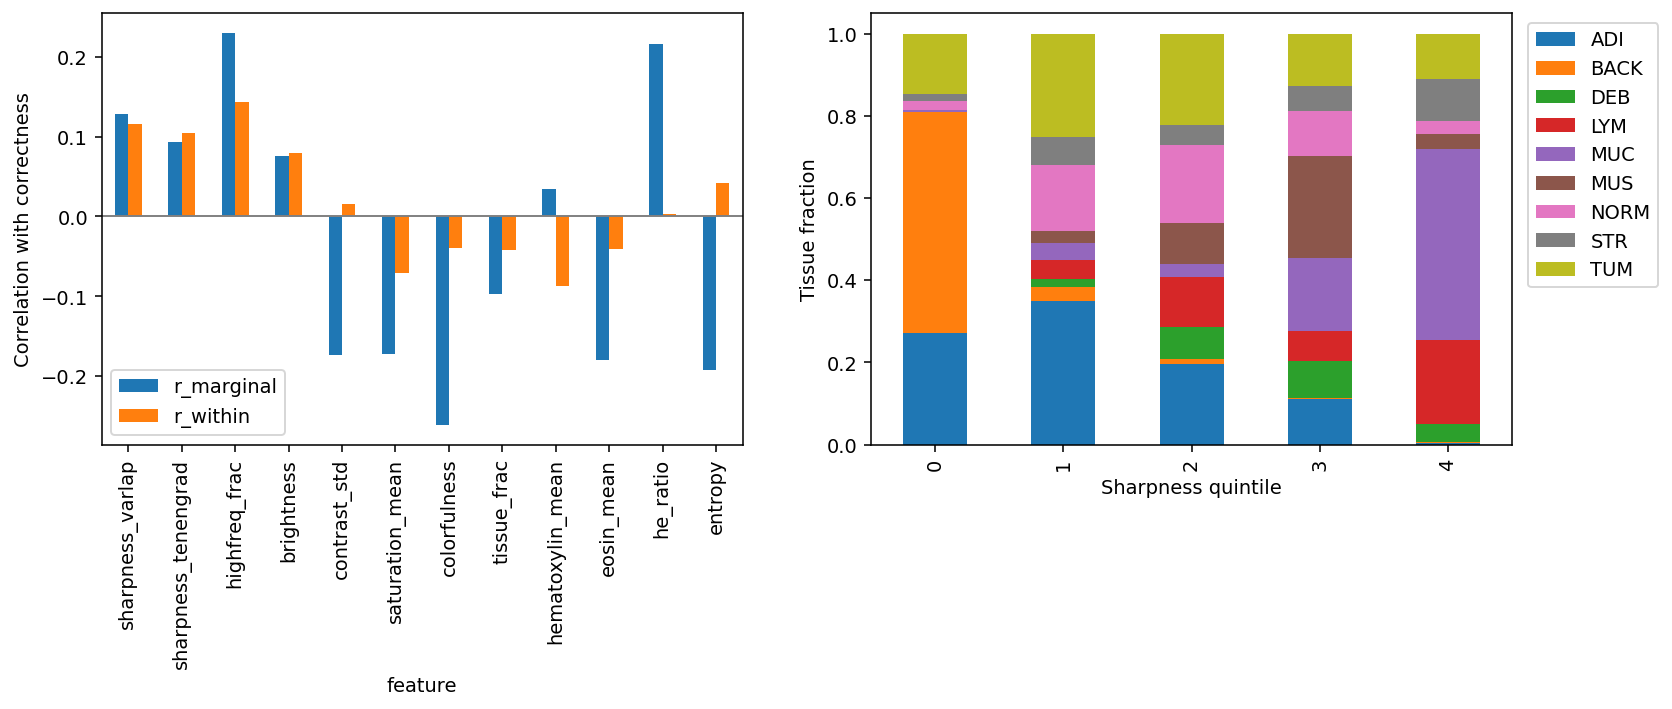

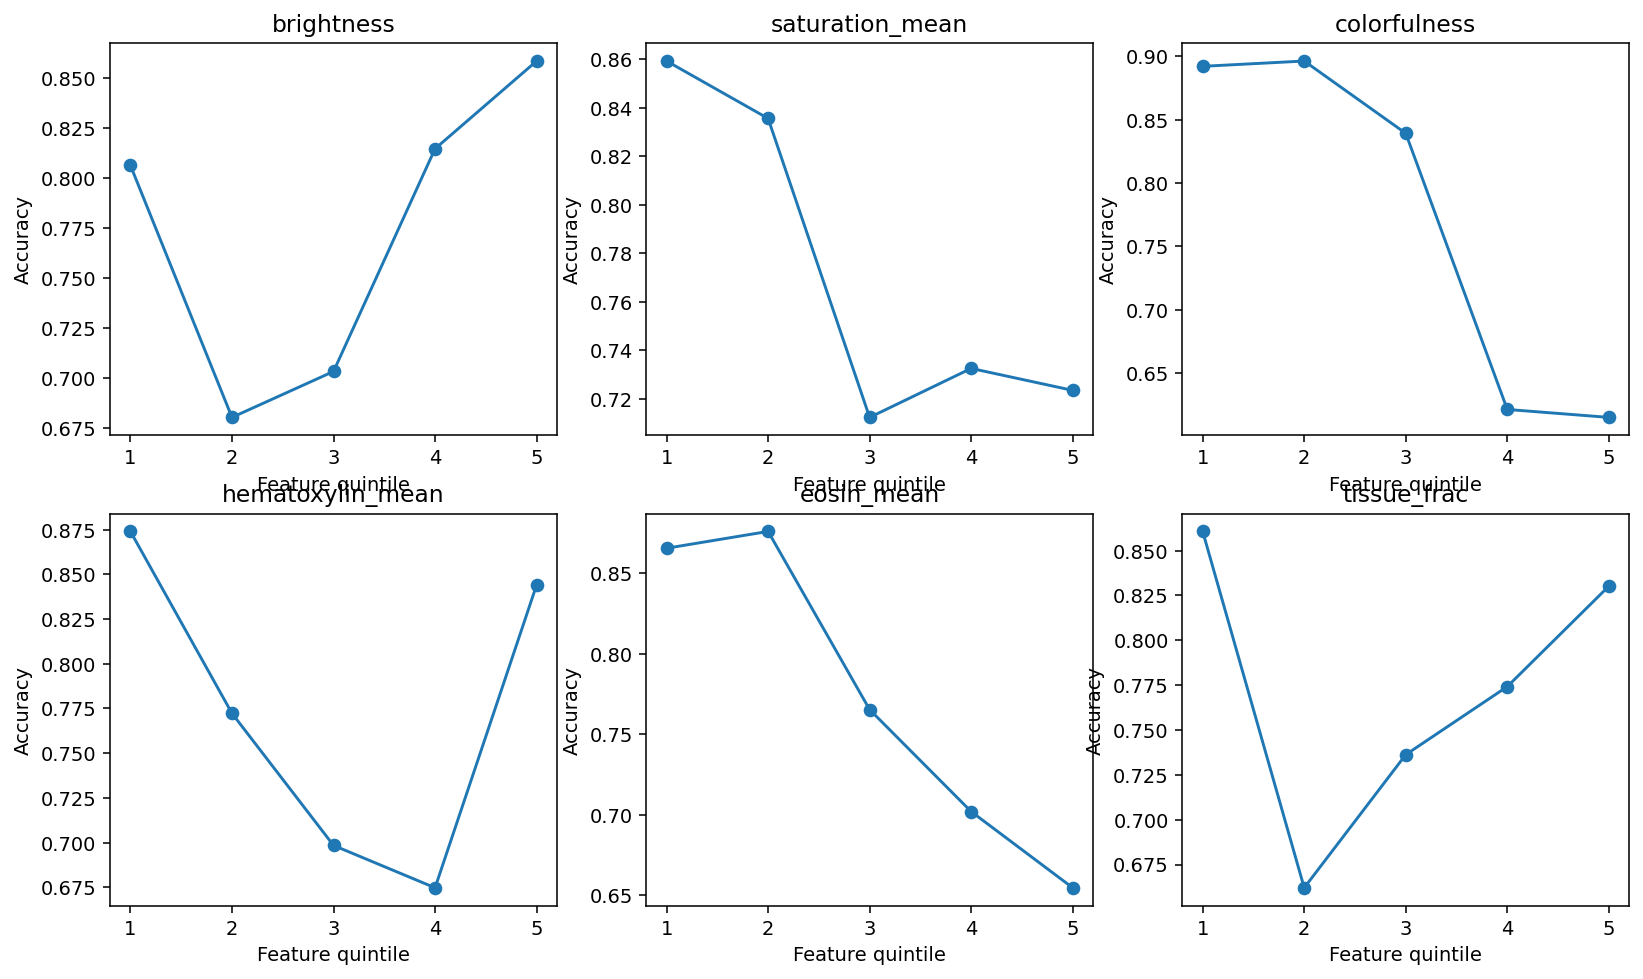

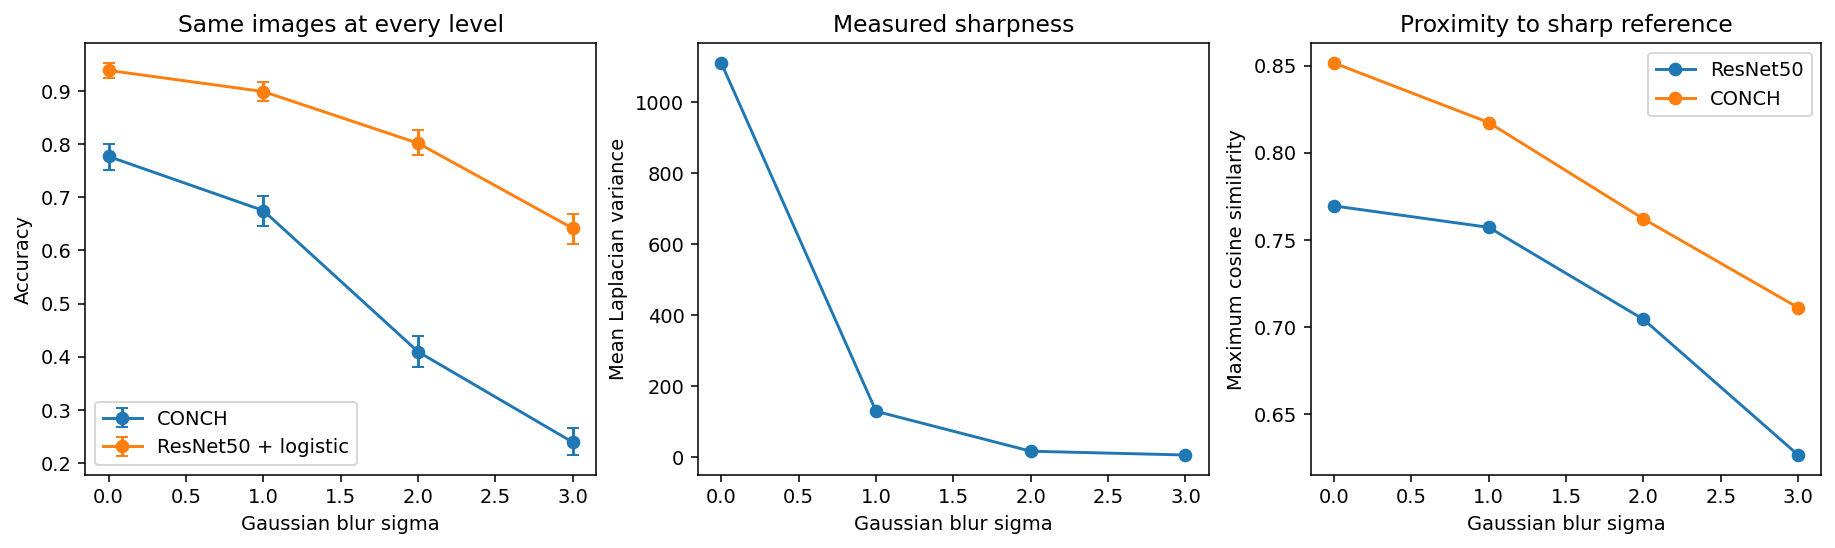

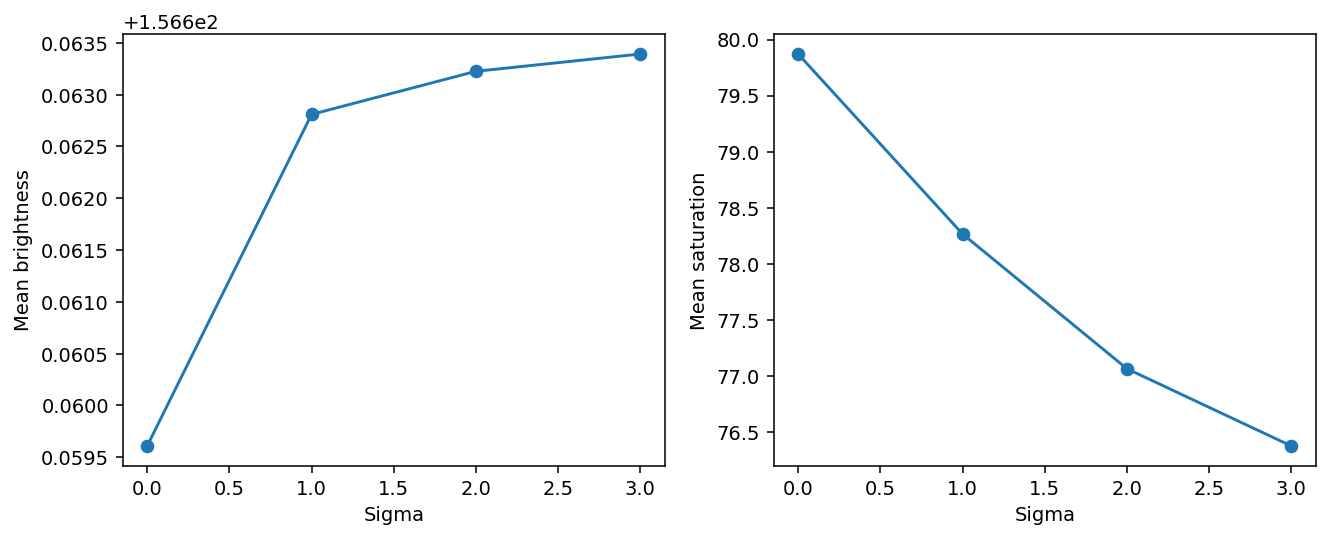

,sigma,conch_acc,conch_ci,baseline_acc,baseline_ci,mean_varlap,mean_conch_prox,mean_resnet_prox,mean_brightness,mean_saturation
0,0.0,0.776852,"[0.7518518518518519, 0.8009259259259259]",0.938889,"[0.924074074074074, 0.9527777777777777]",1110.380558,0.851552,0.769456,156.659608,79.870819
1,1.0,0.675000,"[0.6462962962962963, 0.7027777777777777]",0.899074,"[0.8805555555555555, 0.9175925925925926]",128.291572,0.817363,0.757141,156.662810,78.265143
2,2.0,0.409259,"[0.37962962962962965, 0.43796296296296294]",0.801852,"[0.7796296296296297, 0.825925925925926]",15.671722,0.762020,0.704279,156.663226,77.062943
3,3.0,0.238889,"[0.21481481481481482, 0.26481481481481484]",0.641667,"[0.6129629629629629, 0.6694444444444444]",4.952181,0.710992,0.626348,156.663393,76.373698


sigma,0.0,1.0,2.0,3.0
label_name,,,,
ADI,0.683333,0.808333,0.733333,0.366667
BACK,0.941667,0.941667,0.950000,0.783333
DEB,0.900000,0.433333,0.016667,0.000000
LYM,1.000000,0.991667,0.908333,0.816667
MUC,0.866667,0.708333,0.175000,0.033333
MUS,0.816667,0.625000,0.200000,0.008333
NORM,0.425000,0.283333,0.083333,0.016667
STR,0.508333,0.433333,0.066667,0.033333
TUM,0.850000,0.850000,0.550000,0.091667


,conch_correct,baseline_correct
sigma,,
0.0,0.760494,0.827160
1.0,0.651852,0.856790
2.0,0.367901,0.787654
3.0,0.207407,0.664198


0.8    11.505466
0.9    14.344609
Name: Required total sample size, McNemar approximation, dtype: float64

n_per_level                                                                1080
sigmas                                                     [0.0, 1.0, 2.0, 3.0]
conch_drop                                                             0.537963
conch_drop_ci95                        [0.5074074074074074, 0.5703703703703704]
baseline_drop                                                          0.297222
difference_in_differences                                              0.240741
did_ci95                             [0.20092592592592592, 0.28055555555555556]
monotone_conch                                                             True
varlap_decreases                                                           True
resnet_proximity_decreases                                                 True
pilot_required_sample_size    {'0.8': 11.505465724162574, '0.9': 14.34460856...
dtype: object

4697

In [5]:
from scipy import stats
from math import ceil
screen=[]
for feature in FEATS:
    correlation,pvalue=stats.pointbiserialr(dev.correct,dev[feature]);rs=[];weights=[]
    for cls,part in dev.groupby('label_name'):
        if len(part)>=30 and part.correct.std()>0 and part[feature].std()>0:
            rs.append(stats.pointbiserialr(part.correct,part[feature]).statistic);weights.append(len(part))
    screen.append(dict(feature=feature,r_marginal=float(correlation),p_marginal=float(pvalue),r_within=float(np.average(rs,weights=weights))))
screen=pd.DataFrame(screen).set_index('feature');display(screen)
fig,axs=plt.subplots(1,2,figsize=(13,4));screen[['r_marginal','r_within']].plot.bar(ax=axs[0]);axs[0].set(ylabel='Correlation with correctness');axs[0].axhline(0,color='gray',lw=1)
pd.crosstab(dev.sharpness_varlap_quintile,dev.label_name,normalize='index').plot.bar(stacked=True,ax=axs[1]);axs[1].set(xlabel='Sharpness quintile',ylabel='Tissue fraction');axs[1].legend(bbox_to_anchor=(1.01,1));display_figure(fig)
# Candidate stain curves remain descriptive discovery screens.
fig,axs=plt.subplots(2,3,figsize=(14,8))
for ax,feature in zip(axs.flat,['brightness','saturation_mean','colorfulness','hematoxylin_mean','eosin_mean','tissue_frac']):
    table=dev.groupby(feature+'_quintile').correct.mean();ax.plot(table.index+1,table.values,'o-');ax.set(title=feature,xlabel='Feature quintile',ylabel='Accuracy')
display_figure(fig)

def bootstrap_ci(values,n_boot=4000,seed=1):
    x=np.asarray(values,float);rng=np.random.default_rng(seed);means=x[rng.integers(0,len(x),(n_boot,len(x)))].mean(1)
    return [float(np.quantile(means,.025)),float(np.quantile(means,.975))]
def paired_boot(values,n_boot=5000,seed=0):
    return float(np.mean(values)),bootstrap_ci(values,n_boot,seed)
levels=[]
for sigma,part in scored.groupby('sigma',sort=True):
    levels.append(dict(sigma=float(sigma),conch_acc=float(part.conch_correct.mean()),conch_ci=bootstrap_ci(part.conch_correct),baseline_acc=float(part.baseline_correct.mean()),baseline_ci=bootstrap_ci(part.baseline_correct),mean_varlap=float(part.varlap.mean()),mean_conch_prox=float(part.conch_prox.mean()),mean_resnet_prox=float(part.resnet_prox.mean()),mean_brightness=float(part.brightness.mean()),mean_saturation=float(part.saturation_mean.mean())))
levels=pd.DataFrame(levels)
paired=scored.pivot(index='id',columns='sigma',values=['conch_correct','baseline_correct'])
conch_delta=(paired['conch_correct'][0.]-paired['conch_correct'][3.]).to_numpy(float);base_delta=(paired['baseline_correct'][0.]-paired['baseline_correct'][3.]).to_numpy(float)
conch_drop,conch_ci=paired_boot(conch_delta);did,did_ci=paired_boot(conch_delta-base_delta)
fig,axs=plt.subplots(1,3,figsize=(16,4))
for model,label in [('conch','CONCH'),('baseline','ResNet50 + logistic')]:
    y=levels[model+'_acc'].to_numpy();ci=np.array(levels[model+'_ci'].to_list());axs[0].errorbar(levels.sigma,y,yerr=np.vstack([y-ci[:,0],ci[:,1]-y]),fmt='o-',capsize=3,label=label)
axs[0].set(xlabel='Gaussian blur sigma',ylabel='Accuracy',title='Same images at every level');axs[0].legend()
axs[1].plot(levels.sigma,levels.mean_varlap,'o-');axs[1].set(xlabel='Gaussian blur sigma',ylabel='Mean Laplacian variance',title='Measured sharpness')
axs[2].plot(levels.sigma,levels.mean_resnet_prox,'o-',label='ResNet50');axs[2].plot(levels.sigma,levels.mean_conch_prox,'o-',label='CONCH');axs[2].set(xlabel='Gaussian blur sigma',ylabel='Maximum cosine similarity',title='Proximity to sharp reference');axs[2].legend();display_figure(fig)
fig,axs=plt.subplots(1,2,figsize=(11,4));axs[0].plot(levels.sigma,levels.mean_brightness,'o-');axs[0].set(xlabel='Sigma',ylabel='Mean brightness');axs[1].plot(levels.sigma,levels.mean_saturation,'o-');axs[1].set(xlabel='Sigma',ylabel='Mean saturation');display_figure(fig)
display(levels);display(scored.groupby(['label_name','sigma']).conch_correct.mean().unstack())
# Development pilot power calculation uses paired correct-to-wrong transitions.
pilot_pair=pilot_scored.pivot(index='id',columns='sigma',values='conch_correct');a=pilot_pair[0.].to_numpy();b=pilot_pair[3.].to_numpy();pb=float(((a==1)&(b==0)).mean());pc=float(((a==0)&(b==1)).mean());pdisc=pb+pc
power={}
for target_power in [.8,.9]:
    za=stats.norm.ppf(.975);zb=stats.norm.ppf(target_power)
    power[str(target_power)]=float((za*np.sqrt(pdisc)+zb*np.sqrt(pdisc-(pb-pc)**2))**2/(pb-pc)**2) if abs(pb-pc)>1e-9 else float('inf')
display(pilot_scored.groupby('sigma')[['conch_correct','baseline_correct']].mean());display(pd.Series(power,name='Required total sample size, McNemar approximation'))
scientific_results=dict(n_per_level=1080,sigmas=SIGMAS,conch_drop=conch_drop,conch_drop_ci95=conch_ci,baseline_drop=float(base_delta.mean()),difference_in_differences=did,did_ci95=did_ci,monotone_conch=bool(np.all(np.diff(levels.conch_acc)<=1e-9)),varlap_decreases=bool(np.all(np.diff(levels.mean_varlap)<=0)),resnet_proximity_decreases=bool(np.all(np.diff(levels.mean_resnet_prox)<=1e-6)),pilot_required_sample_size=power)
display(pd.Series(scientific_results));(OUTPUT/'analysis.json').write_text(json.dumps(dict(results=scientific_results,levels=levels.to_dict('records'),feature_screen=screen.reset_index().to_dict('records')),indent=2))

## 6. What the agent decided, and why

A positive paired CONCH loss establishes degradation. Its paired difference from the reference classifier distinguishes greater model sensitivity, shared difficulty, and comparative robustness. Stain and class-composition screens remain controls unless their own independent confirmation exists; a blur intervention cannot establish a stain-distance result.

In [6]:
if AXIS_ID=='test-01':
    if conch_ci[0]<=0:verdict='Reject: the paired CONCH degradation interval does not exclude zero.'
    elif did_ci[1]<0:verdict='Real blur degradation, but reject model-specific weakness: CONCH loses less accuracy than the fixed reference.'
    elif did_ci[0]>0:verdict='Accept the controlled blur axis: CONCH degrades more than the fixed reference.'
    else:verdict='Accept shared controlled blur difficulty; the difference from the fixed reference is not resolved.'
elif AXIS_ID=='test-02':
    verdict='Keep stain descriptors as discovery controls. These screens do not provide an independent stain-distance confirmation; the paired confirmation isolates blur.'
else:
    assert scored.groupby('sigma').label_name.value_counts().unstack().nunique().max()==1
    verdict='Treat tissue composition as a confound of marginal feature curves. The paired blur panel fixes every class count and image across levels.'
print(verdict)
display(pd.Series(dict(decision=verdict,**scientific_results)))

Keep stain descriptors as discovery controls. These screens do not provide an independent stain-distance confirmation; the paired confirmation isolates blur.


decision                      Keep stain descriptors as discovery controls. ...
n_per_level                                                                1080
sigmas                                                     [0.0, 1.0, 2.0, 3.0]
conch_drop                                                             0.537963
conch_drop_ci95                        [0.5074074074074074, 0.5703703703703704]
baseline_drop                                                          0.297222
difference_in_differences                                              0.240741
did_ci95                             [0.20092592592592592, 0.28055555555555556]
monotone_conch                                                             True
varlap_decreases                                                           True
resnet_proximity_decreases                                                 True
pilot_required_sample_size    {'0.8': 11.505465724162574, '0.9': 14.34460856...
dtype: object